# 13 · Stage 4 control: a single sweep never tips

**Purpose.** Simulates one smooth sweep of $R_i$ across its whole range, without return, at many speeds and in both directions, and checks the final state and the switching point. It answers: can one fast pass also leave the circuit in a different final state, or does the tipping of Stage 4 need repeated passes?

**In the report.** Chapter 7, Sec. 7.7 and Fig. 7.7 (a single sweep, simulation).

## Theory

The sweep is a smooth step between 41 and 51 kΩ,

$$R_i(t) = 41\,\mathrm{k\Omega} + 10\,\mathrm{k\Omega}\cdot\tfrac12\left[1 + \tanh\frac{4(t - t_m)}{T}\right], \qquad T = \frac{10\,\mathrm{k\Omega}}{\lambda},$$

or its mirror image from 51 to 41 kΩ. Its rate is $2\lambda$ at the midpoint (46 kΩ) and $2\lambda(1 - 0.2^2) = 1.92\lambda$ at the threshold, 45 kΩ.

A single crossing only delays the switch: raising the gain must end oscillating at full size and lowering it must end quiet, at every rate. The switch-off point follows from the envelope equation (2.13) integrated along this path, with no free parameter: starting at the threshold crossing $t_{45}$, find the time at which

$$\int_{t_{45}}^{t} \frac{\omega_0}{2}\,\bigl(G_c - G(R_i(s))\bigr)\,\mathrm{d}s = \ln 10, \qquad G = 1 + \frac{R_F}{R_i},\ G_c = 3 .$$

Because the rate at threshold is $1.92\lambda$, the switch-off points grow as $\sqrt{\lambda}$ with a coefficient $\sqrt{1.92}$ times the $k_i$ of Eq. (2.33).

## Method

1. **Simulate** (needs LTspice): the configuration-B netlist with the tanh profile as a PWL control voltage (4000 points), a 10 s hold at the end value, saved like the bench files (cropped at the trigger's rising edge, 0.3 ms sampling).
2. **Envelope**: running maximum of $|V|$ over 30 ms, backward and forward windows combined.
3. **Switch-off** (gain falling, 41 → 51 kΩ): the first time after $t_{45}$ that the envelope falls to 10 % of the initial full-size level; **switch-on** (gain rising): the first time after $t_{45}$ that it reaches 90 % of the record's 99th percentile. The resistance at that time comes from the profile above.
4. **Final state**: median envelope over the last 0.2 s of the record, and the envelope at the end of the sweep itself ($t_m + 2T$).
5. **Prediction**: the integral above, solved with `scipy.integrate.quad` and `brentq`.

## Requirements

LTspice 24+, `PyLTSpice`/`spicelib` and `lm741.lib` for the simulation cell; `numpy`, `pandas`, `scipy`, `matplotlib` otherwise.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
RUN_SIMULATION = False
LTSPICE_EXE  = r"C:\Program Files\LTspice.exe"
LM741_LIB    = "lm741.lib"
FOLDER_GAIN_FALLING = "../data/stage4/single_sweep/gain_falling"   # R_i 41 -> 51 kOhm (G falls, quench)
FOLDER_GAIN_RISING  = "../data/stage4/single_sweep/gain_rising"    # R_i 51 -> 41 kOhm (G rises, onset)
SINGLE_SWEEP_RATES = [500, 2000, 5000, 20000, 30000, 35000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]   # nominal lambda, ohm/s
SINGLE_SWEEP_HOLD = 10.0     # s held at the end value
FULL_RESULTS = "../data/stage4/results/single_sweep_summary.csv"   # summary of all 26 report runs, or None
SIM_WORK = "outputs/13_single_sweep/sim_work"
OUT_DIR  = "outputs/13_single_sweep"
T_SETTLE = 2.0; STEP_EDGE = 10e-6; MAXSTEP = 1e-4; DT_OUT = 0.3e-3; NOISE_V = 1e-3
SIM_TIMEOUT = 6 * 3600; RETRY_WITH_GEAR = True; SKIP_EXISTING = True
R_F = 90e3; RI_0 = 41e3; DELTA_RI = 10e3; N_STEPS = 31; STEPS_PER_HALF = 32
R_WIEN, C_WIEN = 2.17e3, 1e-6; G_C = 3.0
ENV_WINDOW = 0.03

## 1. Simulation helpers and the single-sweep runner (needs LTspice to run)

In [2]:
import os, re, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d
from scipy.integrate import quad
from scipy.optimize import brentq
os.makedirs(OUT_DIR, exist_ok=True)
SIM_WORK = os.path.abspath(SIM_WORK)
SINGLE_FOLDERS = {'increment_Ri': os.path.abspath(FOLDER_GAIN_FALLING), 'decrement_Ri': os.path.abspath(FOLDER_GAIN_RISING)}
OMEGA0 = 1 / (R_WIEN * C_WIEN)
STEP_RI = DELTA_RI / N_STEPS
TOP_TAP = min(STEPS_PER_HALF, N_STEPS)

NETLIST = r"""* Wien bridge, R_i swept by a staircase (generated by the notebook)
XU1 N001 inv V+ V- Vout LM741
V1 V+ 0 15
V2 0 V- 15
Vr rctl 0 PWL(0 41)
Vtrig trig 0 PULSE(0 5 {T_SETTLE} 1u 1u 50m 1e6 1)
R1 Vout inv 90k
R2 inv a R=1k*V(rctl)
R3 N002 N001 2.17k
R4 0 N001 2.17k
C1 N001 0 1u
C2 Vout N002 1u
B1 a 0 V={NOISE_V}*white(5e2*time+{{nseed}})
.inc {LM741_LIB}
.param Tstop=10 maxstep=0.1m nseed=0
.tran 0 {{Tstop}} 0 {{maxstep}}
.options plotwinsize=0
.save V(vout) V(trig) V(rctl) V(inv) V(a) I(R2)
.end
"""


def ri_tap_events(tau, t_stop):
    """(time, tap) after every pot change for the configuration-B sketch: 32 decrements (no change at tap 0), then up/down."""
    t_s = T_SETTLE + TRIG_WIDTH                       # sweep starts at the trigger's falling edge
    tap, ev, j = 0, [], 0
    while True:
        t = t_s + j * tau
        if t > t_stop:
            break
        phase = (j // STEPS_PER_HALF) % 2             # 0: decrease block, 1: increase block
        new = max(tap - 1, 0) if phase == 0 else min(tap + 1, TOP_TAP)
        if new != tap:
            ev.append((t, tap, new)); tap = new
        j += 1
    return ev


def write_pwl(points, path):
    times = np.array([p[0] for p in points])
    if not np.all(np.diff(times) > 0):
        raise ValueError("PWL times not strictly increasing")
    with open(path, "w") as fh:
        for t, val in points:
            fh.write(f"{t:.9f} {val:.9f}\n")


def staircase_pwl(tau, t_stop):
    kohm = lambda tap: (RI_0 + STEP_RI * tap) / 1e3
    pts = [(0.0, kohm(0))]
    for t, old, new in ri_tap_events(tau, t_stop):
        pts += [(t, kohm(old)), (t + STEP_EDGE, kohm(new))]
    pts.append((max(pts[-1][0], t_stop) + 1.0, pts[-1][1]))
    return pts


def read_ltspice_raw(path):
    """Binary LTspice raw reader (UTF-16 header; time float64, other traces float32 unless 'double'; FastAccess ok)."""
    size = os.path.getsize(path)
    with open(path, "rb") as fh:
        head = fh.read(min(size, 1 << 20))
    for enc, marker in (("utf-16-le", "Binary:\n".encode("utf-16-le")), ("latin-1", b"Binary:\n")):
        pos = head.find(marker)
        if pos >= 0:
            header, offset = head[:pos].decode(enc, errors="replace"), pos + len(marker)
            break
    else:
        raise ValueError(f"{path}: no 'Binary:' section")
    info, names, in_vars = {}, [], False
    for line in header.splitlines():
        if in_vars:
            p = line.split()
            if len(p) >= 2 and p[0].isdigit():
                names.append(p[1])
            continue
        if line.startswith("Variables:"):
            in_vars = True
        elif ":" in line:
            k, v = line.split(":", 1); info[k.strip()] = v.strip()
    flags = info.get("Flags", "").lower()
    if not names or names[0].lower() != "time":
        raise ValueError(f"{path}: no time axis (plot '{info.get('Plotname')}')")
    nv = len(names); wv = 8 if "double" in flags else 4
    n = (size - offset) // (8 + (nv - 1) * wv)
    cols = {}
    if "fastaccess" in flags:
        n_hdr = int(info.get("No. Points", n)); n = min(n, n_hdr); pos = offset
        for k, nm in enumerate(names):
            w = 8 if k == 0 else wv
            cols[nm] = np.fromfile(path, dtype="<f8" if w == 8 else "<f4", count=n, offset=pos).astype(float)
            pos += w * n_hdr
    else:
        dt_ = np.dtype([("v", "<f8", (nv,))]) if wv == 8 else np.dtype([("t", "<f8"), ("v", "<f4", (nv - 1,))])
        rec = np.memmap(path, dtype=dt_, mode="r", offset=offset, shape=(n,))
        if wv == 8:
            arr = np.array(rec["v"], float); cols = {nm: arr[:, k].copy() for k, nm in enumerate(names)}
        else:
            cols[names[0]] = np.array(rec["t"], float); vv = np.array(rec["v"], float)
            for k, nm in enumerate(names[1:]):
                cols[nm] = vv[:, k].copy()
        del rec
    return {k.lower(): v for k, v in cols.items()}


def run_ltspice_case(stem, pwl_points, t_stop, idx, gear=False):
    from PyLTSpice import SimRunner, SpiceEditor
    from spicelib.simulators.ltspice_simulator import LTspice
    LTspice.create_from(LTSPICE_EXE)
    os.makedirs(SIM_WORK, exist_ok=True)
    base = os.path.join(SIM_WORK, "base_Ri.net")
    with open(base, "w", encoding="ascii") as fh:
        fh.write(NETLIST.format(T_SETTLE=T_SETTLE, NOISE_V=NOISE_V, LM741_LIB=LM741_LIB))
    pwl_path = os.path.join(SIM_WORK, stem + ".pwl")
    write_pwl(pwl_points, pwl_path)
    ed = SpiceEditor(base)
    ed.set_component_value("Vr", f'PWL file="{pwl_path}"')
    ed.set_parameters(Tstop=f"{t_stop:.9g}", maxstep=f"{MAXSTEP:.9g}", nseed=f"{1000 * (idx + 1)}")
    if gear:
        ed.add_instruction(".options method=gear cshunt=1e-15")
    run = SimRunner(output_folder=SIM_WORK, timeout=SIM_TIMEOUT)
    run.run(ed, run_filename=stem + ".net", timeout=SIM_TIMEOUT)
    run.wait_completion()
    raw = os.path.join(SIM_WORK, stem + ".raw")
    if not os.path.exists(raw):
        return None, "no raw file"
    cols = read_ltspice_raw(raw)
    t = np.abs(cols["time"])
    if t[-1] < 0.999 * t_stop:
        return None, f"stopped early at {t[-1]:.3f} s"
    return cols, "ok"


def rf_check(cols):
    i = cols.get("i(r2)"); va = cols.get("v(a)"); vi = cols.get("v(inv)")
    if i is None or va is None or vi is None:
        return np.nan
    ok = np.abs(i) > 1e-7
    return float(np.median(np.abs(np.abs((vi[ok] - va[ok]) / i[ok]) / (1e3 * cols["v(rctl)"][ok]) - 1)))


def save_like_scope(cols, path, t_from):
    """Crop at the trigger's rising edge, shift to t = 0, resample, save as 2 columns without header."""
    t = np.abs(cols["time"]); t, k = np.unique(t, return_index=True)
    v = cols["v(vout)"][k]
    grid = np.arange(t_from, t[-1], DT_OUT)
    out = pd.DataFrame({0: grid - t_from, 1: np.interp(grid, t, v)})
    out.to_csv(path, header=False, index=False, float_format="%.6f")
    return len(out)




def single_sweep_test(rates, mode="decrement_Ri"):
    """Runs smooth tanh sweep of R_i for the selected mode and saves 2-col CSVs."""
    folder = SINGLE_FOLDERS[mode]
    os.makedirs(folder, exist_ok=True)
    rows = []
    for idx, lam in enumerate(rates):
        out_csv = os.path.join(folder, f"time_series_single_{lam:g}.csv")
        dur = DELTA_RI / float(lam)
        t_mid = T_SETTLE + 0.05 + 2.0 * dur
        t_stop = t_mid + 2.0 * dur + SINGLE_SWEEP_HOLD

        if SKIP_EXISTING and os.path.exists(out_csv):
            df_c = pd.read_csv(out_csv, header=None, names=["t", "v"])
            last = df_c["v"][df_c["t"] > (df_c["t"].iloc[-1] - 1.0)].to_numpy()
            rows.append(dict(mode=mode, rate=lam, status="exists (skipped)",
                             final_amplitude_V=0.5 * (last.max() - last.min())))
            print(f"[{mode}] lambda = {lam:g} Ohm/s: exists, skipped")
            continue

        ts = np.linspace(0, t_stop, 4000)
        step = 0.5 * (np.tanh((ts - t_mid) / (dur / 4.0)) + 1.0)
        if mode == "increment_Ri":
            r_k = (RI_0 / 1e3) + (DELTA_RI / 1e3) * step
            seed_idx = 200 + idx
        else:
            r_k = (RI_0 + DELTA_RI) / 1e3 - (DELTA_RI / 1e3) * step
            seed_idx = 100 + idx

        cols, status = None, "not run"
        for gear in ([False, True] if RETRY_WITH_GEAR else [False]):
            cols, status = run_ltspice_case(
                f"single_{mode}_{lam:g}" + ("_gear" if gear else ""),
                list(zip(ts, r_k)), t_stop, seed_idx, gear=gear
            )
            if cols is not None:
                break

        if cols is None:
            rows.append(dict(mode=mode, rate=lam, status=status, final_amplitude_V=np.nan))
            continue

        rc = rf_check(cols)
        n = save_like_scope(cols, out_csv, T_SETTLE)
        t = np.abs(cols["time"])
        v = cols["v(vout)"]
        last = v[t > t_stop - 1.0]
        amp = 0.5 * (last.max() - last.min())
        print(f"   saved {out_csv} ({n} rows), R_i check = {rc:.1e}, final_amp = {amp:.3f} V")
        rows.append(dict(mode=mode, rate=lam, status=status, final_amplitude_V=amp))

    print(pd.DataFrame(rows).to_string(index=False))

In [3]:
if RUN_SIMULATION:
    for mode in SINGLE_FOLDERS:
        single_sweep_test(SINGLE_SWEEP_RATES, mode=mode)
else:
    print("RUN_SIMULATION = False: no LTspice runs.")

RUN_SIMULATION = False: no LTspice runs.


## 2. Analyse the saved runs and compare with the prediction

In [4]:
RF, R0k, DRk = R_F / 1e3, RI_0 / 1e3, DELTA_RI / 1e3          # kOhm
sigma = lambda Rk: 0.5 * OMEGA0 * (1 + RF / Rk - G_C)

def profile(lam, mode):
    dur = DRk * 1e3 / lam; tm = 0.05 + 2 * dur; w = dur / 4
    s = lambda t: 0.5 * (np.tanh((t - tm) / w) + 1)
    R = (lambda t: R0k + DRk * s(t)) if mode == "increment_Ri" else (lambda t: R0k + DRk - DRk * s(t))
    t45 = tm + w * np.arctanh(2 * (0.4 if mode == "increment_Ri" else 0.6) - 1)   # time at which R_i = 45 kOhm
    return R, tm, dur, t45

def env_of(v, n):
    p = np.abs(v); return np.minimum(maximum_filter1d(p, n, origin=(n - 1) // 2), maximum_filter1d(p, n, origin=-(n // 2)))

rows = []
for mode, folder in SINGLE_FOLDERS.items():
    for f in sorted(glob.glob(os.path.join(folder, "time_series_single_*.csv")), key=lambda p: float(re.findall(r"_(\d+)\.csv", p)[0])):
        lam = float(re.findall(r"_(\d+)\.csv", f)[0]); d = pd.read_csv(f, header=None).to_numpy(); t, v = d[:, 0], d[:, 1]
        dt = np.median(np.diff(t)); e = env_of(v, int(ENV_WINDOW / dt)); R, tm, dur, t45 = profile(lam, mode)
        ref = np.median(e[(t > 0.3) & (t < t45 - 0.05)]) if mode == "increment_Ri" else np.percentile(e, 99)
        i45 = np.searchsorted(t, t45)
        idx = np.where(e[i45:] <= 0.1 * ref)[0] if mode == "increment_Ri" else np.where(e[i45:] >= 0.9 * ref)[0]
        tx = t[i45 + idx[0]] if len(idx) else np.nan
        r = dict(mode=mode, lam=lam, R_switch_kohm=R(tx), end_of_sweep_V=float(np.interp(tm + 2 * dur, t, e)),
                 final_V=float(np.median(e[-int(0.2 / dt):])))
        if mode == "increment_Ri":
            g = lambda tt: quad(lambda s: -sigma(R(s)), t45, tt, limit=500)[0] - np.log(10)
            try: r["R_predicted_kohm"] = R(brentq(g, t45 + 1e-6, tm + 3 * dur))
            except ValueError: r["R_predicted_kohm"] = np.nan
        rows.append(r)
res = pd.DataFrame(rows); res.to_csv(os.path.join(OUT_DIR, "single_sweep_summary.csv"), index=False)
print(res.round(3).to_string(index=False))

        mode     lam  R_switch_kohm  end_of_sweep_V  final_V  R_predicted_kohm
increment_Ri  2000.0         46.328           0.014    0.014            46.351
increment_Ri 20000.0         48.955           0.014    0.014            49.000
decrement_Ri  2000.0         43.080          13.911   13.911               NaN
decrement_Ri 20000.0         41.166          13.910   13.911               NaN


## 3. Figure (as Fig. 7.7)

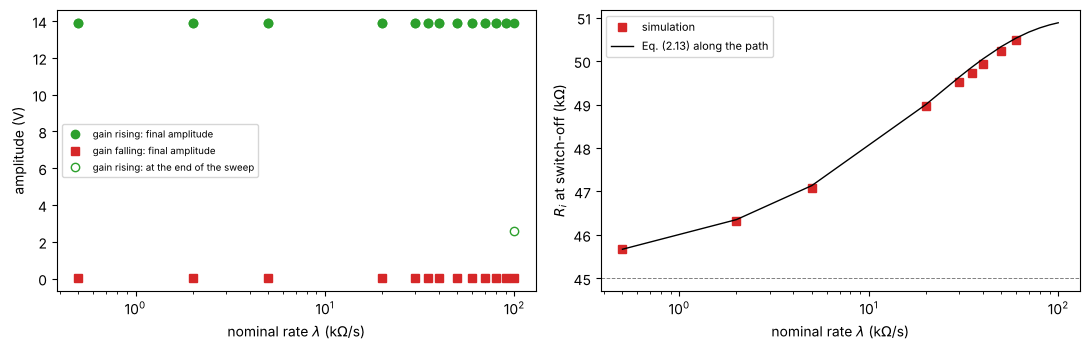

In [5]:
S = pd.read_csv(FULL_RESULTS) if FULL_RESULTS else res
inc, dec = S[S["mode"] == "increment_Ri"], S[S["mode"] == "decrement_Ri"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].semilogx(dec.lam / 1e3, dec.final_V, "o", color="tab:green", label="gain rising: final amplitude")
axs[0].semilogx(inc.lam / 1e3, inc.final_V, "s", color="tab:red", label="gain falling: final amplitude")
axs[0].semilogx(dec.lam / 1e3, dec.end_of_sweep_V, "o", mfc="none", color="tab:green", label="gain rising: at the end of the sweep")
axs[0].set_xlabel(r"nominal rate $\lambda$ (k$\Omega$/s)"); axs[0].set_ylabel("amplitude (V)"); axs[0].legend(fontsize=7)
axs[1].semilogx(inc.lam / 1e3, inc.R_switch_kohm, "s", color="tab:red", label="simulation")
axs[1].semilogx(inc.lam / 1e3, inc.R_predicted_kohm, "k-", lw=1, label="Eq. (2.13) along the path")
axs[1].axhline(45, color="gray", ls="--", lw=0.7); axs[1].set_xlabel(r"nominal rate $\lambda$ (k$\Omega$/s)"); axs[1].set_ylabel(r"$R_i$ at switch-off (k$\Omega$)"); axs[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "single_sweep.png"), dpi=150); plt.show()

## Check against the report

In [6]:
pts = inc.set_index("lam").loc[[500, 2000, 5000, 20000]]
checks = {
    "switch-off points 45.67, 46.33, 47.09, 48.96 kOhm at 0.5, 2, 5, 20 kOhm/s": np.allclose(pts.R_switch_kohm, [45.67, 46.33, 47.09, 48.96], atol=0.006),
    "predicted 45.67, 46.35, 47.13, 49.00 kOhm; agreement within 50 ohm": np.allclose(pts.R_predicted_kohm, [45.67, 46.35, 47.13, 49.00], atol=0.006)
        and (pts.R_switch_kohm - pts.R_predicted_kohm).abs().max() < 0.05,
    "every rising-gain sweep ends at full size (13.9 V) after the hold": np.allclose(dec.final_V, 13.9, atol=0.3),
    "every falling-gain sweep ends quiet": (inc.final_V < 0.1).all(),
    "rate at threshold = 1.92 lambda": abs(2 * (1 - 0.2**2) - 1.92) < 1e-9,
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)

PASS switch-off points 45.67, 46.33, 47.09, 48.96 kOhm at 0.5, 2, 5, 20 kOhm/s
PASS predicted 45.67, 46.35, 47.13, 49.00 kOhm; agreement within 50 ohm
PASS every rising-gain sweep ends at full size (13.9 V) after the hold
PASS every falling-gain sweep ends quiet
PASS rate at threshold = 1.92 lambda


## Using your own circuit

Change the configuration values and, for another profile, the function `profile` (the analysis) together with the PWL built in `single_sweep_test` (the simulation). The prediction assumes the ideal threshold of the simulated circuit, $G_c = 3$.